# A simple variational quantum algorithm: VQE

## The problem

Given a Hamiltonian $H$ (a Hermitian matrix, written as a sum of Pauli strings), find its lowest eigenvalue $E_0$, the **ground-state energy**. Solving this exactly by diagonalization costs memory that grows as $4^n$ for $n$ qubits, which is hopeless for large systems. The **Variational Quantum Eigensolver (VQE)** splits the work: the quantum computer does the part that is hard classically (preparing a state and measuring its energy), and a classical optimizer does the rest.

## The variational principle

For *any* normalized state $|\psi\rangle$, the energy is bounded below by the ground-state energy:

$$E(\psi) = \langle\psi|H|\psi\rangle \;\ge\; E_0.$$

So minimizing $E$ over a family of states gets us closer to $E_0$ from above, and never below it (in the ideal, noiseless case). The better the family, the tighter the bound.

## How it works

1. **Ansatz.** A parameterized circuit $U(\boldsymbol\theta)$ acting on $|0\ldots0\rangle$ prepares a trial state $|\psi(\boldsymbol\theta)\rangle$. The parameters $\boldsymbol\theta$ are rotation angles.
2. **Measure.** Write $H = \sum_k c_k P_k$ with Pauli strings $P_k$. The quantum computer estimates each $\langle P_k\rangle$ from repeated shots (the **Estimator** primitive does this), and we combine them: $E(\boldsymbol\theta) = \sum_k c_k \langle P_k\rangle$.
3. **Optimize.** A classical optimizer (COBYLA, SPSA, gradient descent, ...) proposes new angles to lower $E(\boldsymbol\theta)$.
4. **Repeat** steps 2 and 3 until the energy stops improving.

```
theta --> [ prepare U(theta)|0> ] --> [ measure <H> ] --> E(theta)
  ^                                                          |
  +------------- optimizer updates theta <-------------------+
```

## What this notebook explores

We run the same loop on **two Hamiltonians** (one easy, one hard) with **two ansatzes** (one cheap, one expressive), and compare how well and how quickly each combination converges. At the end we look at **how the jobs are submitted to IBM hardware** (job, session, and batch modes), which decides how long you wait in the queue.

> **Things to keep in mind.** The ansatz sets the ceiling: if the true ground state cannot be reached by $U(\boldsymbol\theta)$, VQE converges to something above $E_0$. Energies are noisy (finite shots, hardware errors), so the optimizer must tolerate noise. The energy landscape can have local minima and flat regions ("barren plateaus"), so the starting point and the ansatz matter.

## Setup

By default this notebook runs only on the noiseless Aer simulator. To also run on IBM hardware, set `skip_hardware=False` below (you need a saved token; see `00-Setup-Start-Here`). Hardware jobs may wait in a queue.

The other settings:

- `n`: the number of qubits in the spin chain (at least 2).
- `maxiter`: the maximum number of COBYLA iterations (each one is one energy evaluation, so one Estimator job).
- `hardware_hamiltonian` and `hardware_modes`: what to run on hardware, and in which execution modes (`"job"`, `"session"`, `"batch"`; see Step 8). The modes run one after another in this notebook. To launch them in parallel, use `scripts/vqa.py` from several terminals.
- `starts`: how many random starting points the batch mode screens.

In [1]:
import sys
import time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit_ibm_runtime import Batch, Session
from qiskit_ibm_runtime import EstimatorV2 as RuntimeEstimator
from scipy.optimize import minimize

# _common.py (in ../scripts) connects to IBM hardware.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
# The next line looks for _common.py in ../scripts.
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _common import connect

SETTINGS = SimpleNamespace(
    shots=4096,
    backend="ibm_rensselaer",
    name="default",                       # saved IBM account name
    skip_hardware=True,                   # set to False to also run on IBM hardware
    hardware_hamiltonian="heisenberg",    # "ising" or "heisenberg"
    hardware_modes=["session"],           # any of "job", "session", "batch"
)

n = 2             # number of qubits in the chain
maxiter = 150      # COBYLA iterations (one energy evaluation each)
starts = 4         # random starting points to screen in batch mode
seed = 1           # random seed for the starting angles

OPTIMIZATION_LEVEL = 3
# Colors are a colorblind-safe pair: one color per ansatz.
ANSATZ_COLOR = {"product": "#0072B2", "entangled": "#D55E00"}

## Step 1: Two Hamiltonians, one easy and one hard

Both are chains of $n$ spins with nearest-neighbor couplings. Qiskit writes a Pauli string with qubit 0 on the *right*, so the helper functions below reverse the label before building each term.

**Ising chain (easy):**

$$H_\text{Ising} = -\sum_i X_i X_{i+1} \;-\; 0.5\sum_i X_i.$$

Every term commutes with every other, so the ground state is simply every qubit in $|+\rangle$. That is a **product state**: no entanglement is needed.

**Heisenberg chain (hard):**

$$H_\text{Heis} = \sum_i \left(X_i X_{i+1} + Y_i Y_{i+1} + Z_i Z_{i+1}\right).$$

This is the antiferromagnetic Heisenberg chain. For two qubits the ground state is the entangled singlet $(|01\rangle - |10\rangle)/\sqrt2$ with $E_0 = -3$. No product state gets below $-1$.

Finally, `exact_ground_energy` diagonalizes $H$ exactly. This is the reference VQE is trying to reach. It is only possible because $n$ is small.

In [2]:
def _chain_terms(num_qubits: int, pauli: str, coeff: float) -> list[tuple[str, float]]:
    # coeff * pauli_i pauli_(i+1) for each neighboring pair.
    terms = []
    for i in range(num_qubits - 1):
        label = ["I"] * num_qubits
        label[i] = label[i + 1] = pauli
        terms.append(("".join(reversed(label)), coeff))  # qubit 0 is rightmost
    return terms


def _field_terms(num_qubits: int, pauli: str, coeff: float) -> list[tuple[str, float]]:
    # coeff * pauli_i for every qubit.
    terms = []
    for i in range(num_qubits):
        label = ["I"] * num_qubits
        label[i] = pauli
        terms.append(("".join(reversed(label)), coeff))
    return terms


def ising_hamiltonian(num_qubits: int) -> SparsePauliOp:
    terms = _chain_terms(num_qubits, "X", -1.0) + _field_terms(num_qubits, "X", -0.5)
    return SparsePauliOp.from_list(terms)


def heisenberg_hamiltonian(num_qubits: int) -> SparsePauliOp:
    terms = []
    for pauli in "XYZ":
        terms += _chain_terms(num_qubits, pauli, 1.0)
    return SparsePauliOp.from_list(terms)


def exact_ground_energy(hamiltonian: SparsePauliOp) -> float:
    return float(np.linalg.eigvalsh(hamiltonian.to_matrix())[0])


hamiltonians = {
    "ising": ising_hamiltonian(n),
    "heisenberg": heisenberg_hamiltonian(n),
}
exact = {name: exact_ground_energy(h) for name, h in hamiltonians.items()}

print("Heisenberg Hamiltonian as Pauli terms:")
print(hamiltonians["heisenberg"])
print()
for name, e0 in exact.items():
    print(f"{name:<10} exact E_0 = {e0:+.4f}")

Heisenberg Hamiltonian as Pauli terms:
SparsePauliOp(['XX', 'YY', 'ZZ'],
              coeffs=[1.+0.j, 1.+0.j, 1.+0.j])

ising      exact E_0 = -2.0000
heisenberg exact E_0 = -3.0000


## Step 2: Two ansatzes, one cheap and one expressive

An ansatz is a circuit with free angles. Its job is to define *which states the optimizer can reach*. We use `ParameterVector` so the angles stay symbolic until we plug in numbers.

**Product ansatz.** One $R_Y(\theta_i)$ rotation per qubit and no entanglement. It has only $n$ parameters and depth 1, so each optimizer step is cheap and the landscape is easy to search. The price is **expressibility**: a product state cannot represent entanglement, so it stalls above $E_0$ whenever the true ground state is entangled.

**Entangled ansatz.** A *hardware-efficient* ansatz: layers of $R_Y$ and $R_Z$ rotations separated by ladders of CX gates. With `reps` repetitions it has $2n(\text{reps}+1)$ parameters. The CX gates entangle neighboring qubits, so it can reach ground states the product ansatz cannot. The price is a bigger search space (more iterations to converge) and extra two-qubit gates, which are the noisiest operations on hardware.

product: 2 parameters
entangled: 12 parameters


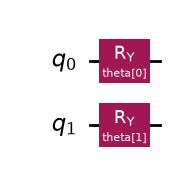

In [3]:
def product_ansatz(num_qubits: int) -> QuantumCircuit:
    theta = ParameterVector("theta", num_qubits)
    circuit = QuantumCircuit(num_qubits, name="product")
    for qubit in range(num_qubits):
        circuit.ry(theta[qubit], qubit)
    return circuit


def entangled_ansatz(num_qubits: int, reps: int = 2) -> QuantumCircuit:
    theta = ParameterVector("theta", 2 * num_qubits * (reps + 1))
    params = iter(theta)
    circuit = QuantumCircuit(num_qubits, name=f"entangled_reps{reps}")
    for layer in range(reps + 1):
        for qubit in range(num_qubits):
            circuit.ry(next(params), qubit)
            circuit.rz(next(params), qubit)
        if layer < reps:
            for qubit in range(num_qubits - 1):
                circuit.cx(qubit, qubit + 1)
    return circuit


ansatzes = {"product": product_ansatz(n), "entangled": entangled_ansatz(n)}
for name, circuit in ansatzes.items():
    print(f"{name}: {circuit.num_parameters} parameters")
ansatzes["product"].draw("mpl")

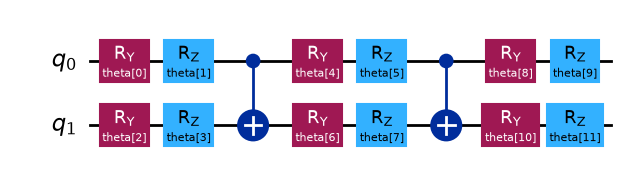

In [4]:
ansatzes["entangled"].draw("mpl")

## Step 3: Transpile for the backend

Hardware only runs a small set of native gates on specific physical qubits. **Transpiling** picks which physical qubits the circuit uses (the *layout*) and rewrites every gate into the native gate set.

Two details matter for VQE:

- The Hamiltonian is defined on the *logical* qubits $0, 1, \ldots$. After transpiling, those logical qubits may live on different physical qubits, so we must map the Hamiltonian onto the same layout with `apply_layout`. Otherwise the Estimator would measure the wrong qubits.
- The angles survive transpiling as symbolic parameters, so we transpile **once**, not once per optimizer step.

Here we transpile for the Aer simulator. The same function works unchanged for an IBM backend.

In [5]:
def transpile_problem(ansatz, hamiltonian, backend):
    pass_manager = generate_preset_pass_manager(
        backend=backend, optimization_level=OPTIMIZATION_LEVEL
    )
    isa_ansatz = pass_manager.run(ansatz)
    isa_hamiltonian = hamiltonian.apply_layout(isa_ansatz.layout)
    print(
        f"  {ansatz.name}: depth {isa_ansatz.depth()}, "
        f"{isa_ansatz.num_nonlocal_gates()} two-qubit gates"
    )
    return isa_ansatz, isa_hamiltonian


aer = AerSimulator()
print("Transpiled for the Aer simulator:")
for name, circuit in ansatzes.items():
    transpile_problem(circuit, hamiltonians["heisenberg"], aer)

Transpiled for the Aer simulator:


  product: depth 1, 0 two-qubit gates
  entangled_reps2: depth 8, 2 two-qubit gates


## Step 4: The cost function

The cost function is the energy $E(\boldsymbol\theta)$. We send the Estimator one PUB, a tuple of

`(circuit, observable, parameter values, precision)`

and it returns the expectation value $\langle H\rangle$ (called `evs`). The Estimator takes a target **standard error** rather than a shot count. For a $\pm1$-valued observable after $N$ shots, the error is about $1/\sqrt N$, so that is the precision we request.

`make_estimator` returns the Aer Estimator for the simulator, or the Runtime Estimator for IBM hardware. Both are called the same way. Let's check the cost function at two starting points.

In [6]:
def make_estimator(backend, mode=None):
    # mode is an open Session or Batch (or None for "job mode"). Ignored on Aer.
    if isinstance(backend, AerSimulator):
        return AerEstimator()
    return RuntimeEstimator(mode=mode if mode is not None else backend)


def energy(estimator, ansatz, hamiltonian, values, shots):
    precision = 1 / np.sqrt(shots)
    job = estimator.run([(ansatz, hamiltonian, values, precision)])
    return job.result()[0].data.evs


estimator = make_estimator(aer)
isa_ansatz, isa_h = transpile_problem(ansatzes["product"], hamiltonians["ising"], aer)
for label, theta in [("all zeros", [0.0, 0.0]), ("all pi/2", [np.pi / 2] * 2)]:
    e = energy(estimator, isa_ansatz, isa_h, np.array(theta), SETTINGS.shots)
    print(f"Ising, product ansatz, theta = {label:<9}: E = {e:+.3f}")
print(f"exact E_0 = {exact['ising']:+.3f}")

  product: depth 1, 0 two-qubit gates
Ising, product ansatz, theta = all zeros: E = -0.008
Ising, product ansatz, theta = all pi/2 : E = -1.995
exact E_0 = -2.000


$\boldsymbol\theta = 0$ leaves every qubit in $|0\rangle$, which has no overlap with the $X$ terms, so $E \approx 0$. Setting every angle to $\pi/2$ turns each qubit into $|+\rangle$, which is exactly the Ising ground state, so $E \approx E_0 = -2$. The optimizer's job is to find that angle without being told.

## Step 5: The optimization loop

`run_vqe` hands the cost function to **COBYLA**, a gradient-free optimizer. Gradient-free methods suit noisy energies because they only need function values. Every call to `cost` is one Estimator job, and the next $\boldsymbol\theta$ depends on the last result. We record every energy it sees in `history`, plus the wall-clock time of the whole loop.

Because every energy is a noisy estimate, the "best" energy is the lowest of many noisy evaluations, so it can fall slightly *below* $E_0$.

In [7]:
def run_vqe(estimator, ansatz, hamiltonian, x0, shots, maxiter):
    history = []

    def cost(theta):
        history.append(float(energy(estimator, ansatz, hamiltonian, theta, shots)))
        return history[-1]

    start = time.perf_counter()
    result = minimize(cost, x0, method="COBYLA", options={"maxiter": maxiter})
    return {
        "history": history,
        "theta": result.x,
        "seconds": time.perf_counter() - start,
    }


def convergence_summary(history, target, tol=0.05):
    hit = next((i + 1 for i, e in enumerate(history) if e <= target + tol), None)
    reached = (
        f"within {tol} of E_0 after {hit} evaluations"
        if hit
        else f"never within {tol} of E_0"
    )
    return f"best {min(history):+.4f}, {reached}"

## Step 6: Run both ansatzes on both Hamiltonians

Now the experiment. For each Hamiltonian and each ansatz we transpile once, pick a random starting point, and run the loop on the noiseless Aer simulator. Results go into the `results` dictionary, keyed by `(hamiltonian, mode)`, so we can compare them later against the hardware modes.

In [8]:
results = {}   # (hamiltonian name, mode) -> {ansatz name: record}


def starting_point(num_parameters):
    return np.random.default_rng(seed).uniform(0, 2 * np.pi, num_parameters)


for ham_name, hamiltonian in hamiltonians.items():
    print(f"\n=== {ham_name} chain, exact E_0 = {exact[ham_name]:+.4f} ===")
    records = {}
    for name, ansatz in ansatzes.items():
        isa_ansatz, isa_h = transpile_problem(ansatz, hamiltonian, aer)
        out = run_vqe(
            estimator, isa_ansatz, isa_h,
            starting_point(ansatz.num_parameters), SETTINGS.shots, maxiter,
        )
        records[name] = {"parameters": ansatz.num_parameters, **out}
        print(
            f"  {name:<9} {len(out['history'])} jobs in {out['seconds']:.1f} s; "
            + convergence_summary(out["history"], exact[ham_name])
        )
    results[(ham_name, "aer")] = records


=== ising chain, exact E_0 = -2.0000 ===
  product: depth 1, 0 two-qubit gates


  product   35 jobs in 0.1 s; best -2.0391, within 0.05 of E_0 after 11 evaluations


  entangled_reps2: depth 8, 2 two-qubit gates


  entangled 130 jobs in 0.3 s; best -2.0135, within 0.05 of E_0 after 37 evaluations

=== heisenberg chain, exact E_0 = -3.0000 ===
  product: depth 1, 0 two-qubit gates
  product   33 jobs in 0.1 s; best -1.0236, never within 0.05 of E_0
  entangled_reps2: depth 8, 2 two-qubit gates


  entangled 114 jobs in 0.3 s; best -3.0158, within 0.05 of E_0 after 43 evaluations


## Step 7: Plot the convergence

Each curve is the energy the optimizer saw at each evaluation. The black line is the exact $E_0$.

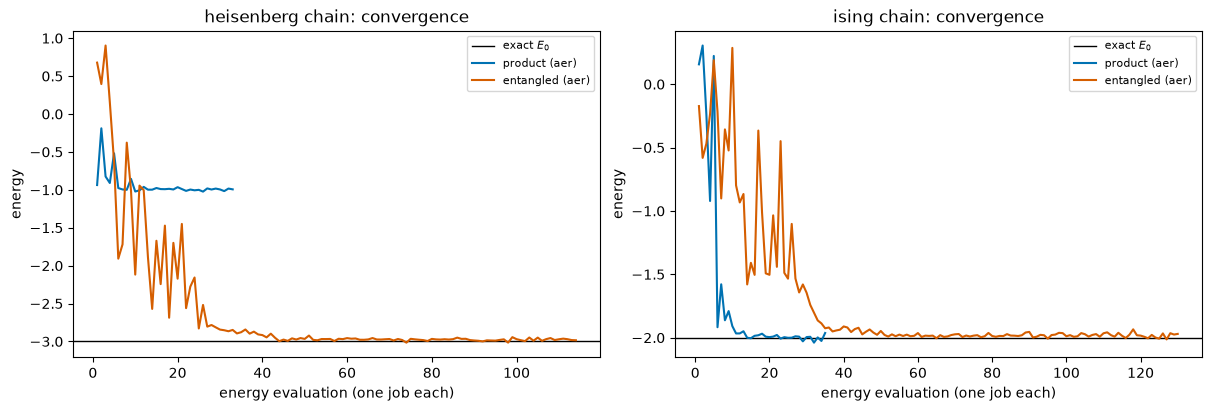

In [9]:
MODE_STYLE = {"aer": "-", "job": ":", "session": "--", "batch": "-."}


def plot_convergence(results):
    ham_names = sorted({h for h, _ in results})
    fig, axes = plt.subplots(1, len(ham_names), figsize=(6 * len(ham_names), 4),
                             squeeze=False, constrained_layout=True)
    for ax, ham_name in zip(axes[0], ham_names):
        ax.axhline(exact[ham_name], color="black", lw=1, label="exact $E_0$")
        for (h, mode), records in results.items():
            if h != ham_name or mode == "batch":
                continue
            for name, rec in records.items():
                ax.plot(range(1, len(rec["history"]) + 1), rec["history"],
                        color=ANSATZ_COLOR[name], ls=MODE_STYLE[mode], lw=1.5,
                        label=f"{name} ({mode})")
        ax.set(title=f"{ham_name} chain: convergence",
               xlabel="energy evaluation (one job each)", ylabel="energy")
        ax.legend(fontsize=8)
    plt.show()


plot_convergence(results)

### Reading the plot

- **Heisenberg (hard).** The product ansatz settles at $E \approx -1$ within a few dozen evaluations and stays there: it is stuck at the best product-state energy, a gap of 2 above $E_0$, no matter how long it runs. The entangled ansatz takes longer, but it reaches $E_0 = -3$.
- **Ising (easy).** The ground state is a product state, so the cheap ansatz is enough, and it gets there in far fewer evaluations. The entangled ansatz can represent the answer too, but it has many more parameters to search, so it needs several times more evaluations. With other starting points it can also stall just short of $E_0$ in a local minimum, or because shot noise swamps the last small improvements.

This is the central trade-off of VQE: **expressibility** (can the ansatz represent the answer?) against **cost** (parameters to optimize, and two-qubit gates to run). A bigger ansatz is not automatically better.

## Step 8: Execution modes on IBM hardware

Every energy evaluation is a small Runtime job, and a VQE run needs dozens. **How those jobs are grouped decides how long you wait in the queue.**

| Mode | What it does | Best for |
|---|---|---|
| **Job** (no context) | Each evaluation is queued on its own. After every optimizer step the next job goes to the back of the queue, so 50 steps can mean 50 waits. | A single one-off job |
| **Session** | Reserves the backend for you for the duration of the loop. Jobs start one after another with no new queue wait, and each one can depend on the last result. | **Iterative loops like VQE** |
| **Batch** | Sends a set of jobs that are all known *in advance* and lets the service schedule them together, in parallel where it can. There is no exclusive access, so a loop where job $k+1$ needs the result of job $k$ gains nothing. | Independent work, such as screening many random starting points |

**Rule of thumb:** dependent jobs (an optimizer loop) go in a **session**; independent jobs go in a **batch**; a single one-off job needs neither.

Because a batch cannot run an optimizer loop efficiently, the batch mode below does something different: it evaluates several random starting points as independent jobs, all submitted before any result is read (`screen_starts`). That is the pattern batches are built for.

The function `run_on_hardware` runs one mode for one Hamiltonian and returns records in the same format as Step 6. The next cell runs it only if `skip_hardware=False`.

In [10]:
def screen_starts(estimator, ansatz, hamiltonian, start_points, shots):
    # Submit every job first, then read the results: the batch-friendly pattern.
    precision = 1 / np.sqrt(shots)
    jobs = [estimator.run([(ansatz, hamiltonian, x0, precision)]) for x0 in start_points]
    return np.array([job.result()[0].data.evs for job in jobs], dtype=float)


def run_on_hardware(mode, ham_name):
    backend = connect(SETTINGS.backend, SETTINGS.name)
    if backend is None:
        return None
    context = {"session": Session, "batch": Batch}.get(mode)
    context = context(backend=backend) if context else None
    records = {}
    try:
        hw_estimator = make_estimator(backend, context)
        for name, ansatz in ansatzes.items():
            isa_ansatz, isa_h = transpile_problem(ansatz, hamiltonians[ham_name], backend)
            if mode == "batch":
                points = np.random.default_rng(seed).uniform(
                    0, 2 * np.pi, (starts, ansatz.num_parameters)
                )
                t0 = time.perf_counter()
                energies = screen_starts(hw_estimator, isa_ansatz, isa_h, points,
                                         SETTINGS.shots)
                records[name] = {
                    "parameters": ansatz.num_parameters,
                    "energies": energies.tolist(),
                    "seconds": time.perf_counter() - t0,
                }
                print(f"  {name:<9} {starts} independent jobs in "
                      f"{records[name]['seconds']:.1f} s; best start {energies.min():+.4f}")
            else:
                out = run_vqe(hw_estimator, isa_ansatz, isa_h,
                              starting_point(ansatz.num_parameters),
                              SETTINGS.shots, maxiter)
                records[name] = {"parameters": ansatz.num_parameters, **out}
                print(f"  {name:<9} {len(out['history'])} jobs in {out['seconds']:.1f} s; "
                      + convergence_summary(out["history"], exact[ham_name]))
    finally:
        if context is not None:
            context.close()
    return records


if SETTINGS.skip_hardware:
    print("skip_hardware=True: set it to False in Setup to run on IBM hardware.")
else:
    for mode in SETTINGS.hardware_modes:
        print(f"\n=== {SETTINGS.hardware_hamiltonian}, {mode} mode on {SETTINGS.backend} ===")
        records = run_on_hardware(mode, SETTINGS.hardware_hamiltonian)
        if records is not None:
            results[(SETTINGS.hardware_hamiltonian, mode)] = records

skip_hardware=True: set it to False in Setup to run on IBM hardware.


## Step 9: Compare everything

Two panels summarize every run in `results` (the Aer runs, plus any hardware modes you ran):

- **Wall-clock time** of each optimizer loop. On hardware, this is where the queue shows up: compare job mode against session mode.
- **Gap above the exact energy**, $E_\text{best} - E_0$ (lower is better). Batch-screened starting points appear as ✕ marks, because batch mode only evaluates starting points and does not optimize.

On the simulator the times are tiny because there is no queue. On hardware, expect job mode to be much slower than session mode for the same number of evaluations, and expect noise to lift the hardware energies above the Aer ones. The entangled ansatz has more two-qubit gates, so noise affects it more.

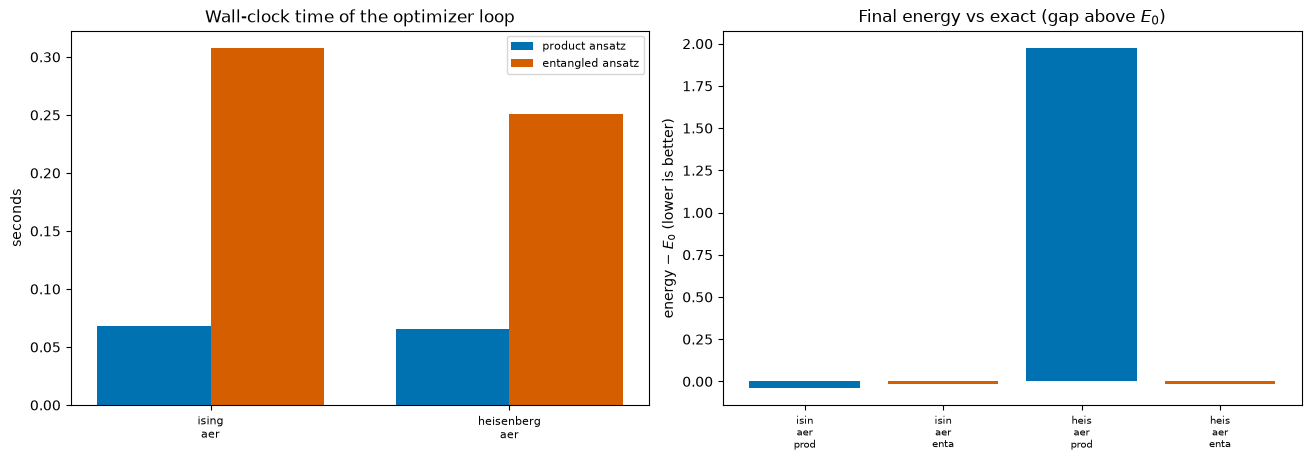

In [11]:
def plot_summary(results):
    loops = [(k, r) for k, r in results.items() if k[1] != "batch"]
    screens = [(k, r) for k, r in results.items() if k[1] == "batch"]
    fig, (ax_t, ax_g) = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

    # Left: wall-clock time of each loop.
    width = 0.38
    for j, name in enumerate(ANSATZ_COLOR):
        xs = np.arange(len(loops)) + (j - 0.5) * width
        ax_t.bar(xs, [rec[name]["seconds"] for _, rec in loops], width,
                 color=ANSATZ_COLOR[name], label=f"{name} ansatz")
    ax_t.set_xticks(np.arange(len(loops)), [f"{h}\n{m}" for (h, m), _ in loops], fontsize=8)
    ax_t.set(title="Wall-clock time of the optimizer loop", ylabel="seconds")
    ax_t.legend(fontsize=8)

    # Right: how far above the exact energy each run ended.
    labels, i = [], 0
    for (h, m), rec in loops:
        for name in ANSATZ_COLOR:
            ax_g.bar(i, min(rec[name]["history"]) - exact[h], color=ANSATZ_COLOR[name])
            labels.append(f"{h[:4]}\n{m}\n{name[:4]}")
            i += 1
    for (h, _), rec in screens:
        for name, r in rec.items():
            ax_g.scatter([i] * len(r["energies"]), np.array(r["energies"]) - exact[h],
                         color=ANSATZ_COLOR[name], marker="x", zorder=3)
        labels.append("batch\nstarts")
        i += 1
    ax_g.set_xticks(np.arange(len(labels)), labels, fontsize=7)
    ax_g.set(title="Final energy vs exact (gap above $E_0$)",
             ylabel="energy $-$ $E_0$ (lower is better)")
    plt.show()


plot_summary(results)

## Summary and things to try

- VQE turns "find the ground-state energy" into "minimize $E(\boldsymbol\theta)$," using the variational principle $E(\boldsymbol\theta) \ge E_0$.
- The **ansatz** decides what is reachable. A product ansatz is cheap but cannot reach an entangled ground state. An entangled ansatz can, at the cost of more parameters, more iterations, and noisier circuits.
- On hardware, **session** mode suits the dependent jobs of an optimizer loop, and **batch** mode suits independent jobs known in advance.

Try these:

1. Set `n = 3` or `4` and rerun. Does the product ansatz still stall on the Heisenberg chain? (The exact diagonalization gets slower, but is fine at this size.)
2. Change `entangled_ansatz(n)` to `entangled_ansatz(n, reps=1)`. How do the number of parameters, the number of evaluations, and the final energy change?
3. Change `seed` and rerun the Ising chain. The product ansatz can start in a flat region near $\boldsymbol\theta = 0$ and get stuck. This is a small example of a bad starting point.
4. Lower `SETTINGS.shots` to 256. How does shot noise change the curves?
5. Set `skip_hardware=False` and try `hardware_modes=["job", "session"]` with a small `maxiter` such as 30. Compare the loop times.